In [2]:
from pathlib import Path


def _resolve_examples_dir() -> Path:
    cwd = Path.cwd().resolve()

    for candidate in (cwd, *cwd.parents):
        if candidate.name == "benchmark":
            return candidate

        examples_dir = candidate / "benchmark"
        if examples_dir.is_dir():
            return examples_dir

    raise RuntimeError("Could not locate benchmark directory")


examples_dir = _resolve_examples_dir()
output_dir = examples_dir / "supplementary"
output_dir.mkdir(parents=True, exist_ok=True)

print(f"Outputs will be saved to: {output_dir}")


Outputs will be saved to: C:\Users\k.lukyanov\Desktop\Programs\Sion\benchmark\supplementary


# Benchmark: ion-number scaling and MPI/OpenMP parallelism

This notebood performs the benchmark of the simulation step scaling with the increasing ion number in the same setup. Set `STEPS=1`, run the sweep, then set `STEPS=10001` in the configuration cell and rerun the configuration, sweep, and analysis cells. Both phases save into the same `BENCHMARK_ID` under distinct filenames. The final analysis subtracts the **median one-step execution time** from the **median 10001-step execution time** for each matching ion-count/MPI/OpenMP configuration and divides by 10000. This way we differentiate between the time for simulation initialization and the actual computing time during the simulation. 

**Performance metric:** 
$$t_{\rm inc}=\frac{T_{10001}-T_{1}}{10000}.$$
This measures the incremental time of `sim.execute()` per additional step; it is *not* pure integration-kernel time. Python-side model construction and voltage optimization occur outside the timed section. For meaningful subtraction, the one-step and long-run phases use the same initial positions and dump settings.


In [3]:
from __future__ import division
import sion.pylion as pl
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt, numpy as np, scipy.constants as ct
from mpl_toolkits.mplot3d import Axes3D
from sion.electrode import (System, PolygonPixelElectrode, PointPixelElectrode, shaped)
import time

import sion as sn


## Trap initialization

Initialize the five-wire trap with 7 side DC electrodes for confinement of a large ion number.

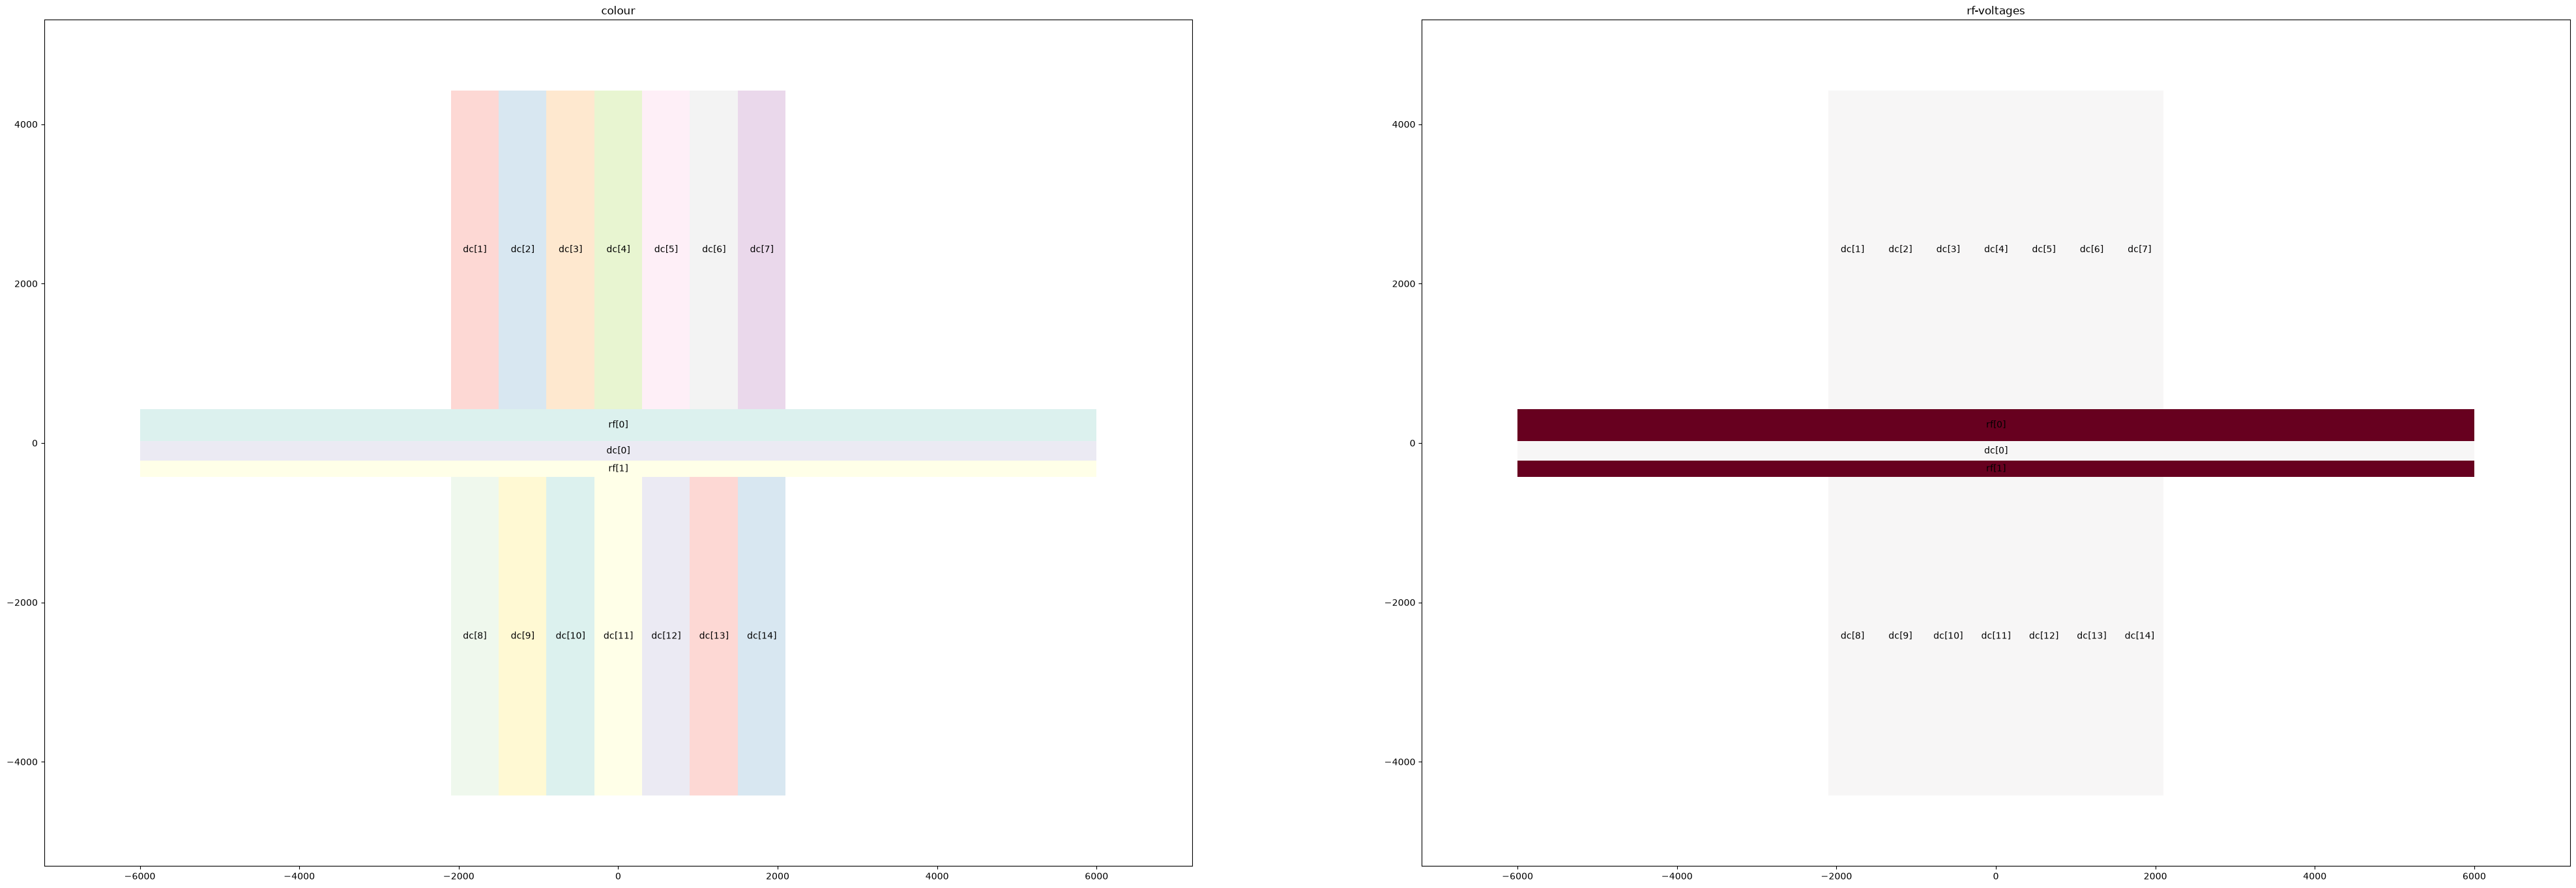

In [4]:
# Global definition of trap parameters. Used for all cells in this notebook
L = 1e-6 # µm length scale
Vrf = 500 # RF peak voltage in V
Omega = 2*np.pi*30e6 # RF frequency in rad/s
M = 40*ct.atomic_mass # ion mass
Z = 1*ct.elementary_charge # ion charge
# RF voltage in parametrized form so that the resulting potential equals the RF pseudopotential in eV
Urf = Vrf*np.sqrt(Z/M)/(2*L*Omega)


#parameters of trap
top_dc = [[600, 4000]]*7
          
bottom_dc = top_dc #Array of lengths and widths of Bottom electrodes 
top_rf = [12000, 400]  #length of central dc, rf electrode
central_dc = [12000, 250]
bottom_rf =  [12000, 200]

gap = 0


s, RF_coordinates, DC_coordinates = sn.five_wire_trap_design(Urf, top_dc ,bottom_dc, top_rf, bottom_rf, central_dc, gap=gap,
                                                            need_coordinates = True, need_plot = True, figsize=(50,30))  #save_plot = 'linear_shuttling_trap.png'

## Potential characterization

The following block is used for potential characterisation to refine the potential for trapping of large ion crystals

Initial loss = 63.2799117985412


Optimizing voltages: 17it [00:00, 33.73it/s]

Final loss = 7.796644252345013e-16
Final uset = [np.float64(-1.0301156688894737), np.float64(9.984904048348808), np.float64(4.167627341264425), np.float64(-4.76642091531678), np.float64(-9.85372094510792), np.float64(-4.765463793630691), np.float64(4.168011156648138), np.float64(9.985087549022575), np.float64(9.991150833585754), np.float64(4.377974053047124), np.float64(-1.7485469159255347), np.float64(-3.697623164470238), np.float64(-1.7489458046688535), np.float64(4.378601346347657), np.float64(9.989820167411134)]
For Calcium:
The minimum is (-3.3e-09, -141, 217)
Distance from RF-minimum: (-3.3e-09, -1.62e-08, -2.25e-08) um
Secular frequencies: (0.3813, 4.32, 4.361) MHz
In directions
a: [1.00000000e+00 6.44210273e-07 1.61767279e-07] 
b: [-6.57228651e-07  9.94913649e-01  1.00731478e-01] 
c: [-9.60522211e-08 -1.00731478e-01  9.94913649e-01]
Angle of secular modes rotation alpha: 0.10090261150854889
Mathieu frequencies: (0.3813, 4.477, 4.52) MHz


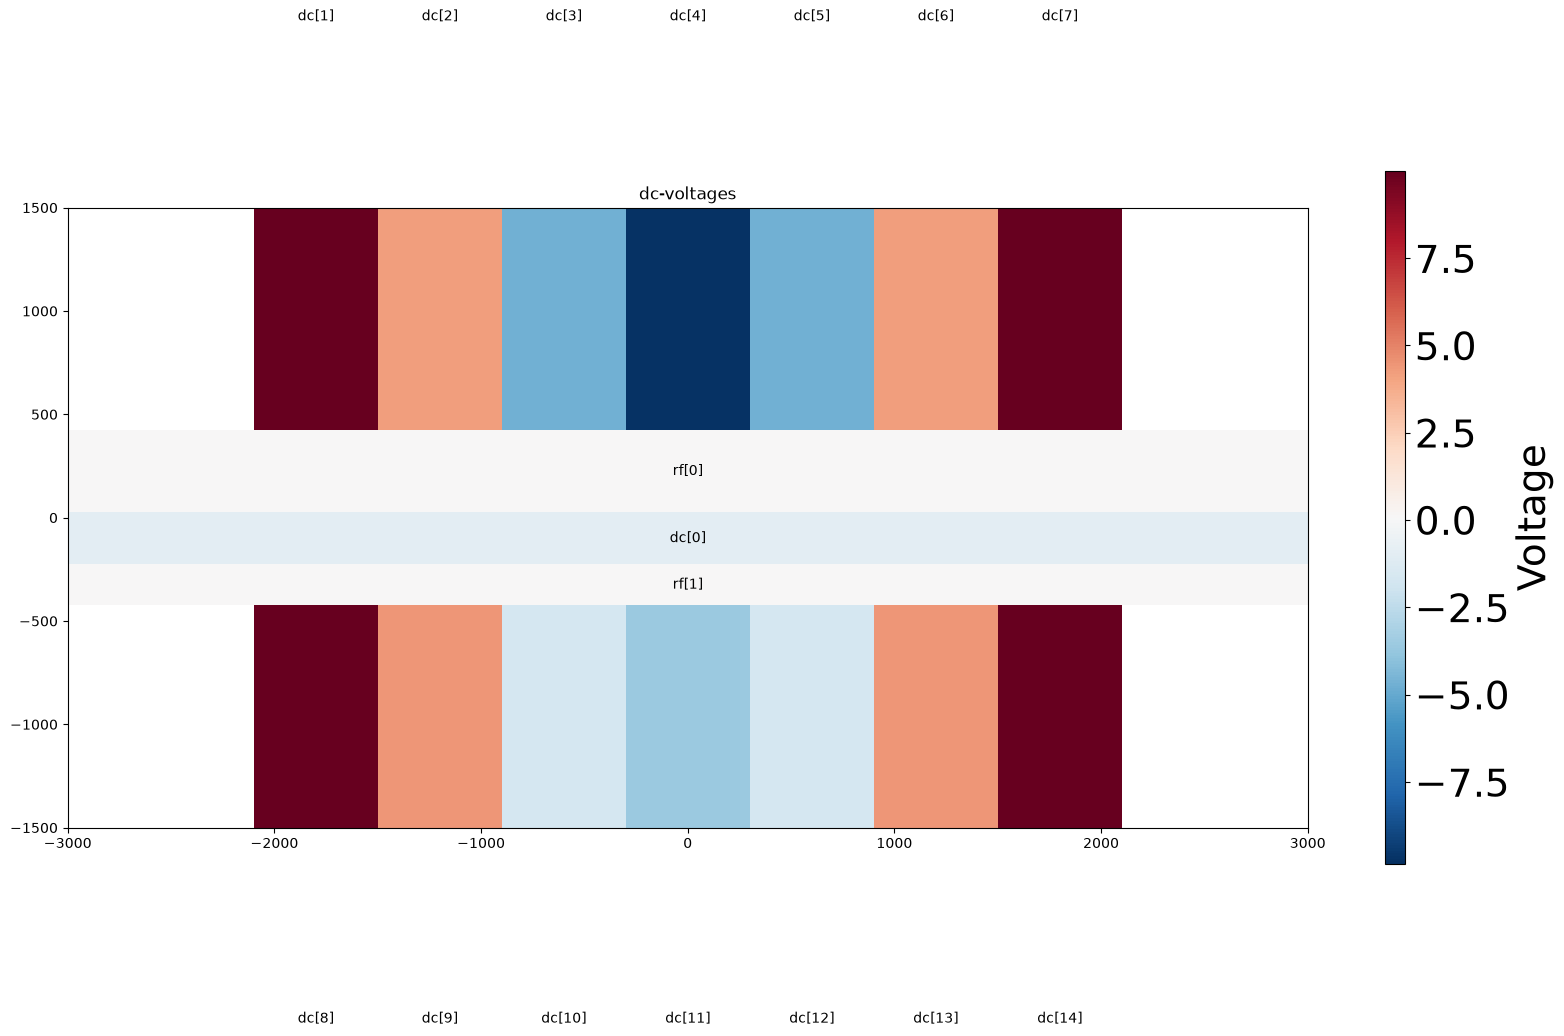

In [5]:
x0 = s.minimum([0,0,82.45], axis=(0, 1, 2), coord=np.identity(3), method="Newton-CG", options={'maxiter': 1000000})
start_dc_set = np.array([-0.15, 11, 4,-5, -10, -5, 4, 11, 11, 4,-3, -6, -3, 4, 11])
u_set = np.append(np.zeros(2), start_dc_set)
rf_set = [Vrf, Vrf]
omegas = [Omega]*2

dc_set = sn.position_optimization(s, [[x0[0], x0[1], x0[2]]], start_dc_set, eps=1e-2, tol=1e-36, numbers=0, 
                          ion_masses=M, charges=1, callback_num=100, voltage_bounds=(-10,10))   #voltage search

u_set = np.append(np.zeros(2), dc_set)


with s.with_voltages(dcs = u_set, rfs = None):
    print('For Calcium:')
    x1 = s.minimum(x0*1.001, axis=(0, 1, 2), coord=np.identity(3), method="Newton-CG")
    print('The minimum is (%.3g, %.3g, %.3g)' % (x1[0], x1[1], x1[2]))
    print('Distance from RF-minimum: (%.3g, %.3g, %.3g) um' % (x1[0] - x0[0], x1[1] - x0[1], x1[2] - x0[2]))
    # Get trap frequencies
    try:
        omega_sec, mod_dir = sn.single_ion_modes(s, x1, M)
        omega_sec *= 1e-6
        print("Secular frequencies: (%.4g, %.4g, %.4g) MHz" % (omega_sec[0],omega_sec[1],omega_sec[2]))
        print("In directions\na:", mod_dir[0],"\nb:", mod_dir[1],"\nc:", mod_dir[2] )
        e1 = np.array([0,0,1])
        alp = np.arccos(np.inner(mod_dir[2],e1))
        print('Angle of secular modes rotation alpha:', alp)
        
        omega_mathieu, mathieu_modes = sn.single_ion_modes(s, x1, M, mathieu=True, Omega=Omega)
        omega_mathieu *= 1e-6
        print("Mathieu frequencies: (%.4g, %.4g, %.4g) MHz" % (omega_mathieu[0],omega_mathieu[1],omega_mathieu[2]))
    except:
        print("Secular frequencies not found")

with s.with_voltages(dcs = u_set):    
    
    fig, ax = plt.subplots(1,1, figsize=(20, 10))
    s.plot_voltages(ax, u=s.dcs)
    #u = s.dcs sets the voltage-type for the voltage plot to DC-voltages (RF are not shown)
    xmax = 3000
    ymaxn = 1500
    ymaxp = 1500
    ax.set_title("dc-voltages")
    ax.set_aspect('equal')
    ax.set_xlim(-xmax, xmax)
    ax.set_ylim(-ymaxn, ymaxp)
    #Add colorbar
    cmap = plt.cm.RdBu_r
    norm = mpl.colors.Normalize(vmin=np.min(u_set), vmax=np.max(u_set))

    cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink = 0.9, aspect = 35)
    
    """cb = plt.colorbar(ax=ax[2], shrink=0.9)"""
    cb.ax.tick_params(labelsize=28)
    cb.set_label('Voltage', fontsize = 28)


RF pseudopotential minimum: -0.824 eV at (-6.98e-08, -141, 217)µm
secular frequencies: (0.3813, 4.32, 4.361) MHz
in directions
a: [1.00000000e+00 6.44305374e-07 1.61491868e-07] 
b: [-6.57251404e-07  9.94959879e-01  1.00273820e-01] 
c: [-9.60709682e-08 -1.00273820e-01  9.94959879e-01]
Rotation angle = 0.1


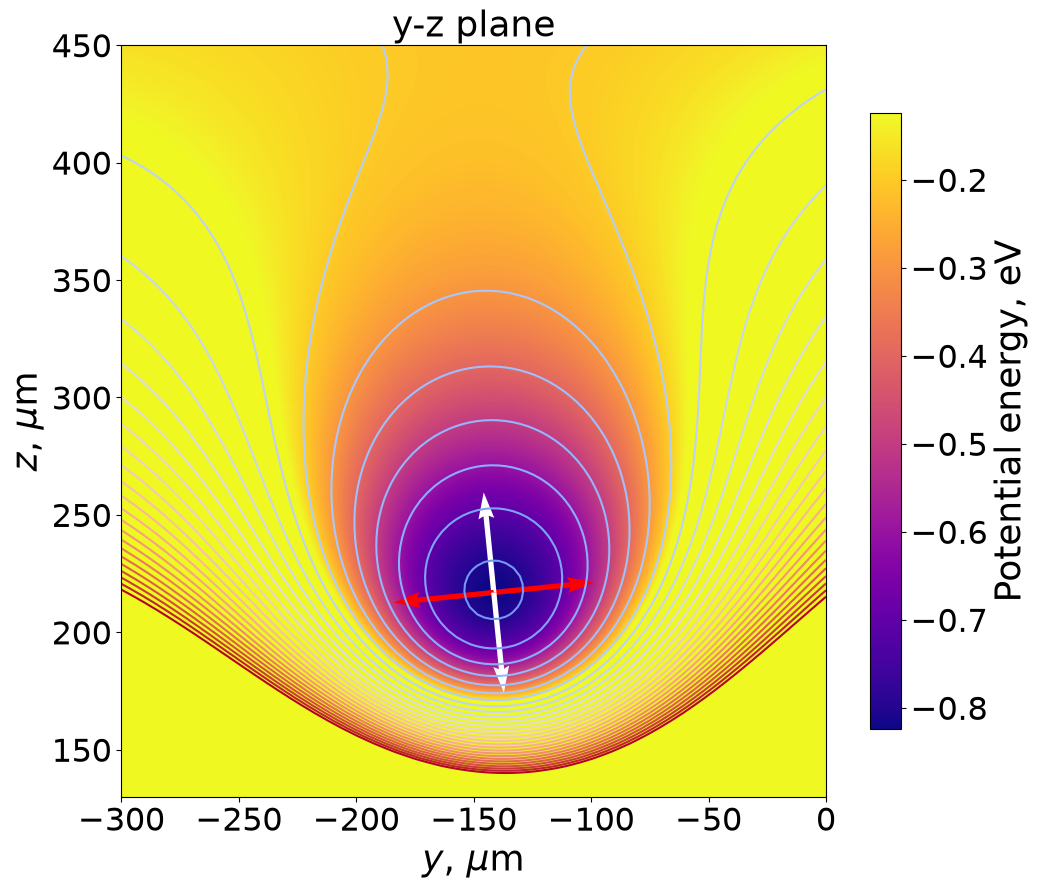

In [6]:
mass = M
with s.with_voltages(dcs = u_set, rfs = None):
#     try:81.
    x0 = s.minimum(x1*1.0001, axis=(0, 1, 2), coord=np.identity(3), method="Newton-CG")
    p_tot0=s.potential(x0, 0)[0]
    print("RF pseudopotential minimum: %.4g" % p_tot0,"eV at (%.3g, %.3g, %.3g)µm" % (x0[0], x0[1], x0[2]))
#     except:
#         x0 = x_ini

    curv_z, mod_dir=s.modes(x0,sorted=False)
    omega_sec = np.sqrt(Z*curv_z/mass)/(2*np.pi)
    print("secular frequencies: (%.4g, %.4g, %.4g) MHz" % (omega_sec[0],omega_sec[1],omega_sec[2]))
    print("in directions\na:", mod_dir[0],"\nb:", mod_dir[1],"\nc:", mod_dir[2] )

    # 2D plot settings

    n=100 # resolution of meshgrid = resolution of 2D plots
    xmin, xmax = -1050, 900 #set the plot ranges
    ymin, ymax = -300, 0
    zmin, zmax = 130, 450
    x_cut, y_cut, z_cut = x0[0], x0[1], x0[2]# position of the yz-, xz-, xy- crossection
    v = np.arange(-1.4, 2., 0.1)# set the range for contour lines (range in eV)
    v_min, v_max = p_tot0, p_tot0 + 0.7  #set the range for colour map (range in eV)
    fs = 26 #set the fontsize
    ls = 23 #set the labelsize
    fig = plt.figure()
    fig.set_size_inches(25,10)

    # # y-z cross section
    ax3 = plt.subplot2grid((2,2), (0,1), rowspan=2)
    ax3.set_title("y-z plane" ,fontsize=fs)
    ax3.set_xlabel('$y$, $\\mu$m',fontsize=fs)
    ax3.set_ylabel('$z$, $\\mu$m',fontsize=fs)
    ax3.tick_params(axis='x', labelsize=ls)
    ax3.tick_params(axis='y', labelsize=ls)
    xyz = np.mgrid[x_cut:x_cut+1, ymin:ymax:1j*n, zmin:zmax:1j*n]
    pot = shaped(s.potential)(xyz)
    x, z, p = (_.reshape(n, n) for _ in (xyz[1], xyz[2], pot))
    CS=ax3.contour(x, z, p, v, cmap=plt.cm.coolwarm)
    im = ax3.imshow(p.T,cmap='plasma', origin='lower', vmin=v_min, vmax=v_max, extent=(ymin,ymax,zmin,zmax))
    im.set_interpolation('bilinear') 
    # ax3.set_yticks([60e-6, 80e-6, 100e-6, 120e-6, 140e-6], [60 ,80 ,100, 120, 140])
    # ax3.set_xticks([-60e-6, -40e-6, -20e-6, 0, 20e-6, 40e-6, 60e-6], [-60, -40, -20, 0, 20, 40, 60])
    # add colorbar
    cb = fig.colorbar(im, ax=ax3, shrink=0.8)
    cb.ax.tick_params(labelsize=ls)
    cb.set_label('Potential energy, eV', fontsize = fs)

    ax3.quiver(*[[x0[1]],[x0[2]]], mod_dir[1][1], mod_dir[1][2], color=['r'], scale = 7)
    ax3.quiver(*[[x0[1]],[x0[2]]], mod_dir[2][1], mod_dir[2][2], color=['w'], scale = 7)
    ax3.quiver(*[[x0[1]],[x0[2]]], -mod_dir[1][1], -mod_dir[1][2], color=['r'], scale = 7)
    ax3.quiver(*[[x0[1]],[x0[2]]], -mod_dir[2][1], -mod_dir[2][2], color=['w'], scale = 7)
    print(f'Rotation angle = {np.round(np.arccos(mod_dir[1][1]), 3)}')

## Polygon trap simulation

The following block defines the simulation function used for the benchmark

In [ ]:
# Benchmark configuration and setup.
import csv
import hashlib
import importlib.metadata
import json
import os
import platform
import random
import subprocess
import sys
import traceback
from datetime import datetime, timezone

# Keep this ID fixed to resume the same experiment; change it to start a new dataset.
BENCHMARK_ID = "time_to_ion_scaling1"
bench_dir = output_dir / BENCHMARK_ID
cases_dir = bench_dir / "cases"
logs_dir = bench_dir / "simulations"
cases_dir.mkdir(parents=True, exist_ok=True)
logs_dir.mkdir(parents=True, exist_ok=True)

ION_NUMBERS = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512, 1024, 2048]
#note that it is not recommended to exceed the number of physical cores for large computational problems. This configuration is made for my particular workstation.
MPI_PROCESSES = [1, 2, 4, 8, 16, 24, 40]
OMP_THREADS_BY_MPI = {p: [1, 2, 4, 8] if p == 1 else [1] for p in MPI_PROCESSES}  
# PROCESS_PAIRS = [(1, 1), (2, 1), (4, 1), (8, 1), (16, 1), (24, 1), (40, 1), 
#                  (2, 2), (4, 2), (4, 4), (8, 4), (16, 2), (20, 2), (40, 2) ]
STEPS = 1      # Run with 1 first, then change to 10001 and rerun cells 9, 11, 13-15
REPEATS = 3         
DUMP_EVERY = 1   # None for compute-oriented timing, or 1 for the trajectory output
POSITION_SEED = 20261104
ORDER_SEED = 20261104

x0 = np.asarray(x1, dtype=float) * 1e-6

# Cache identical starting positions across process counts, repeats, and resumed runs.
positions_path = bench_dir / "initial_positions.npz"
if positions_path.exists():
    with np.load(positions_path) as z:
        POSITIONS_BY_N = {n: np.array(z[str(n)], copy=True) for n in ION_NUMBERS}
else:
    np.random.seed(POSITION_SEED)
    random.seed(POSITION_SEED)
    POSITIONS_BY_N = {
        n: np.asarray(sn.ioncloud_min(x0, n, 150e-6), dtype=float)
        for n in ION_NUMBERS
    }
    np.savez_compressed(positions_path, **{str(n): x for n, x in POSITIONS_BY_N.items()})


def _package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def _git_commit():
    try:
        return subprocess.check_output(
            ["git", "rev-parse", "HEAD"], cwd=examples_dir,
            stderr=subprocess.DEVNULL, text=True, timeout=3,
        ).strip()
    except (OSError, subprocess.SubprocessError):
        return None


metadata_file = bench_dir / "metadata.json"
metadata = {
    "protocol": "SION polygon-trap benchmark; end-to-end Python execute() wall time",
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "ion_numbers": ION_NUMBERS,
    "mpi_processes": MPI_PROCESSES,
    "omp_threads_by_mpi_rank": OMP_THREADS_BY_MPI,
    "simulation_steps": [1, 10001],
    "repeats_when_created": REPEATS,
    "dump_every": DUMP_EVERY,
    "position_seed": POSITION_SEED,
    "position_file_sha256": hashlib.sha256(positions_path.read_bytes()).hexdigest(),
    "machine": {
        "platform": platform.platform(),
        "processor": platform.processor(),
        "logical_cpus": os.cpu_count(),
        "python": sys.version,
    },
    "software": {
        "sion_distribution": _package_version("surface-ion"),
        "numpy": np.__version__,
        "scipy": _package_version("scipy"),
        "lammps_version": "RECORD MANUALLY FROM LAMMPS OUTPUT",
        "mpi_version": "RECORD MANUALLY (e.g. MS-MPI)",
        "sion_git_commit": _git_commit(),
    },
    "notes": "Ensure stable power settings, no competing CPU load; record physical core count and CPU model manually if absent."
}
if metadata_file.exists():
    existing = json.loads(metadata_file.read_text(encoding="utf-8"))
    keys = ("ion_numbers", "mpi_processes", "dump_every", "position_seed", "position_file_sha256")
    mismatch = [key for key in keys if existing.get(key) not in (None, metadata[key])]
    if mismatch:
        raise ValueError(f"The existing benchmark ID uses different settings: {mismatch}. Change BENCHMARK_ID for a new experiment.")
    metadata["created_utc"] = existing.get("created_utc", metadata["created_utc"])
metadata_file.write_text(json.dumps(metadata, indent=2), encoding="utf-8")


def _atomic_json(path: Path, result: dict):
    """Write one result atomically so completed cases survive interruption."""
    tmp = path.with_name(path.name + ".tmp")
    with tmp.open("w", encoding="utf-8") as file:
        json.dump(result, file, indent=2)
        file.flush()
        os.fsync(file.fileno())
    os.replace(tmp, path)


def simulation_benchmark(ion_number, mpi_processes, omp_threads=1, repeat=0,
                         steps=STEPS, dump_every=DUMP_EVERY):
    case_tag = f"N{ion_number}_mpi{mpi_processes}_omp{omp_threads}_rep{repeat}_steps{steps}"
    sim = pl.Simulation(str(logs_dir / case_tag))  # unique generated simulation/log names

    Caions = {"mass": 40, "charge": 1}
    sim.append(pl.placeions(Caions, np.array(POSITIONS_BY_N[ion_number], copy=True)))
    sim.append(sn.polygon_trap(omegas, rf_set, dc_set, RF_coordinates, DC_coordinates))
    sim.append(pl.langevinbath(0, 5e-6))

    if dump_every is not None:
        sim.append(pl.dump(
            str(logs_dir / f"dump_{case_tag}.txt"),
            variables=["x", "y", "z"], steps=int(dump_every)
        ))
    sim.append(pl.evolve(int(steps)))

    start = time.perf_counter()
    sim.execute(mpi_processes=int(mpi_processes), omp_threads=int(omp_threads))
    return time.perf_counter() - start

print(f"Benchmark directory: {bench_dir}")
print(f"Jobs for {STEPS} step(s): {len(ION_NUMBERS) * sum(map(len, OMP_THREADS_BY_MPI.values())) * REPEATS}; "
      f"MPI/OMP pairs: {[(p, t) for p in MPI_PROCESSES for t in OMP_THREADS_BY_MPI[p]]}")
print("Before a long run, test TWO consecutive jobs in this kernel and inspect LAMMPS logs.")


Benchmark directory: C:\Users\k.lukyanov\Desktop\Programs\Sion\benchmark\supplementary\time_to_ion_scaling1
Jobs for 10001 step(s): 231; MPI/OMP pairs: [(1, 1), (1, 2), (1, 4), (1, 8), (2, 1), (4, 1), (8, 1)]
Before a long run, test TWO consecutive jobs in this kernel and inspect LAMMPS logs.


## Restartable benchmark sweep

Runs `STEPS=1` or `STEPS=10001`, as selected in the configuration cell. Every completed case is saved as a separate JSON file and skipped on rerun. Keep `BENCHMARK_ID`, `DUMP_EVERY`, and the initial positions identical for both phases; only change `STEPS`. The Python `execute()` timer includes process startup, setup, execution and output.

In [ ]:
jobs = [(n, m, t, r) for n in ION_NUMBERS for m in MPI_PROCESSES
        for t in OMP_THREADS_BY_MPI[m] for r in range(REPEATS)]
random.Random(ORDER_SEED).shuffle(jobs)

completed = 0
for idx, (ion_number, mpi, omp, rep) in enumerate(jobs, start=1):
    case_tag = f"N{ion_number}_mpi{mpi}_omp{omp}_rep{rep}_steps{STEPS}"
    record_path = cases_dir / f"{case_tag}.json"
    if record_path.exists():
        previous = json.loads(record_path.read_text(encoding="utf-8"))
        if previous.get("status") == "ok":
            completed += 1
            print(f"[{idx}/{len(jobs)}] SKIP {case_tag} ({previous['execute_wall_s']:.2f} s)", flush=True)
            continue

    result = {
        "case": case_tag,
        "ion_number": ion_number,
        "mpi_processes": mpi,
        "omp_threads": omp,
        "repeat": rep,
        "steps": STEPS,
        "dump_every": DUMP_EVERY,
        "started_utc": datetime.now(timezone.utc).isoformat(),
    }
    print(f"[{idx}/{len(jobs)}] RUN  {case_tag}", flush=True)
    try:
        wall_s = simulation_benchmark(
            ion_number=ion_number, mpi_processes=mpi,
            omp_threads=omp, repeat=rep,
            steps=STEPS, dump_every=DUMP_EVERY,
        )
        result.update(status="ok", execute_wall_s=float(wall_s),
                      amortized_wall_s_per_step=float(wall_s / STEPS))
        completed += 1
        print(f"   DONE {wall_s:.3f} s ({wall_s/STEPS:.5g} s/step)", flush=True)
    except Exception as exc:
        result.update(status="failed", error=repr(exc), traceback=traceback.format_exc())
        print(f"   FAILED {type(exc).__name__}: {exc}", flush=True)
    finally:
        result["finished_utc"] = datetime.now(timezone.utc).isoformat()
        _atomic_json(record_path, result)

print(f"Successful cases: {completed}/{len(jobs)}. Records in: {cases_dir}")


[1/231] RUN  N8_mpi1_omp2_rep1_steps10001
Reducing timestep to 2.652582384864922e-10 sec
[parallel] 1 MPI × 2 OMP
LAMMPS (10 Dec 2025)
  using 2 OpenMP thread(s) per MPI task
Loaded 1 plugins from C:\Users\k.lukyanov\AppData\Local\LAMMPS 64-bit 10Dec2025-MSMPI with Python\plugins
Created orthogonal box = (-0.01 -0.01 -0.01) to (0.01 0.01 0.01)
  1 by 1 by 1 MPI processor grid
Created 1 atoms.
  create_atoms CPU = 0.000 seconds
Created 1 atoms.
  create_atoms CPU = 0.000 seconds
Created 1 atoms.
  create_atoms CPU = 0.000 seconds
Created 1 atoms.
  create_atoms CPU = 0.000 seconds
Created 1 atoms.
  create_atoms CPU = 0.000 seconds
Created 1 atoms.
  create_atoms CPU = 0.000 seconds
Created 1 atoms.
  create_atoms CPU = 0.000 seconds
Created 1 atoms.
  create_atoms CPU = 0.000 seconds
Setting atom values ...
  8 settings made for charge
8 atoms in group 1
8 atoms in group nonRigidBody
Generated 0 of 0 mixed pair_coeff terms from geometric mixing rule
Neighbor list info ...
  update: eve

## Postprocessing: elapsed time for the selected number of steps

This cell summarizes the current `STEPS` run; the **last analysis cell** combines the one-step and 10001-step medians. The existing plots remain diagnostics for the selected phase, not startup-subtracted measurements.

In [10]:
import pandas as pd

records = [json.loads(path.read_text(encoding="utf-8"))
           for path in sorted(cases_dir.glob("*.json"))]
if not records:
    print("No benchmark results saved yet.")
else:
    raw = pd.DataFrame(records)
    ok = raw.loc[raw.status.eq("ok") & raw.steps.eq(STEPS)].copy()
    print(f"Successful: {len(ok)}; failed: {sum(raw.status.eq('failed'))}")
    if not ok.empty:
        ok.to_csv(bench_dir / f"results_steps{STEPS}.csv", index=False)
        grouped = (ok.groupby(["ion_number", "mpi_processes", "omp_threads"], as_index=False)
                     .agg(t_wall_step_median=("amortized_wall_s_per_step", "median"),
                          t_wall_step_std=("amortized_wall_s_per_step", "std"),
                          repeats=("repeat", "count")))
        baseline = (grouped.loc[(grouped.mpi_processes == 1) & (grouped.omp_threads == 1),
                                ["ion_number", "t_wall_step_median"]]
                    .rename(columns={"t_wall_step_median": "baseline_s_per_step"}))
        grouped = grouped.merge(baseline, on="ion_number", how="left")
        grouped["speedup"] = grouped.baseline_s_per_step / grouped.t_wall_step_median
        grouped["efficiency"] = grouped.speedup / (grouped.mpi_processes * grouped.omp_threads)
        display(grouped)
        grouped.to_csv(bench_dir / f"summary_steps{STEPS}.csv", index=False)


Successful: 231; failed: 0


,ion_number,mpi_processes,omp_threads,t_wall_step_median,t_wall_step_std,repeats,baseline_s_per_step,speedup,efficiency
0,1,1,1,0.131875,0.013211,3,0.131875,1.000000,1.000000
1,1,1,2,0.140148,0.014380,3,0.131875,0.940969,0.470484
2,1,1,4,0.133596,0.016287,3,0.131875,0.987118,0.246779
3,1,1,8,0.136252,0.014475,3,0.131875,0.967877,0.120985
4,1,2,1,0.135713,0.013515,3,0.131875,0.971720,0.485860
...,...,...,...,...,...,...,...,...,...
72,1024,1,4,0.330111,0.012909,3,0.324186,0.982051,0.245513
73,1024,1,8,0.327108,0.024240,3,0.324186,0.991067,0.123883
74,1024,2,1,0.324303,0.029113,3,0.324186,0.999637,0.499818
75,1024,4,1,0.361484,0.004965,3,0.324186,0.896819,0.224205


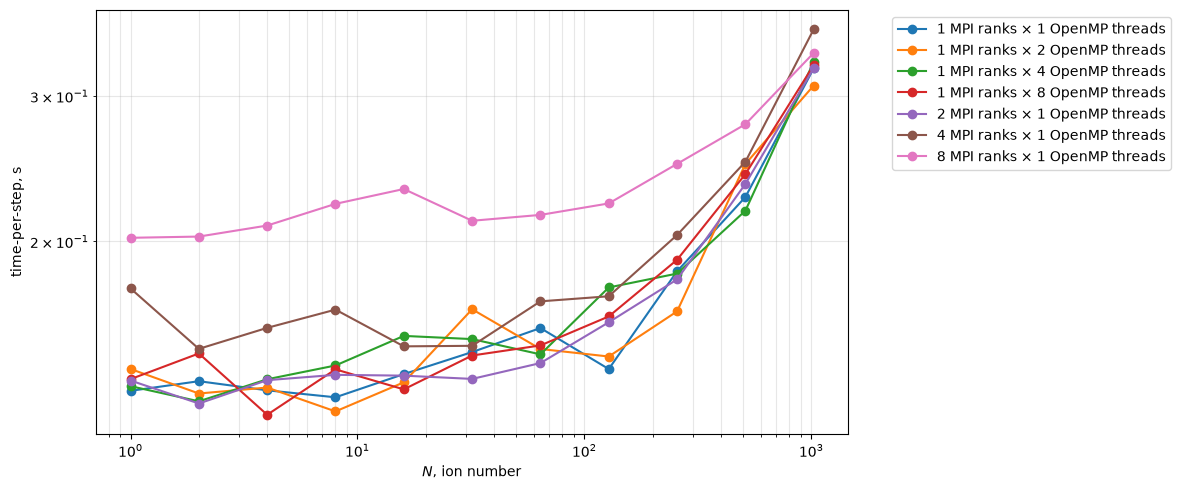

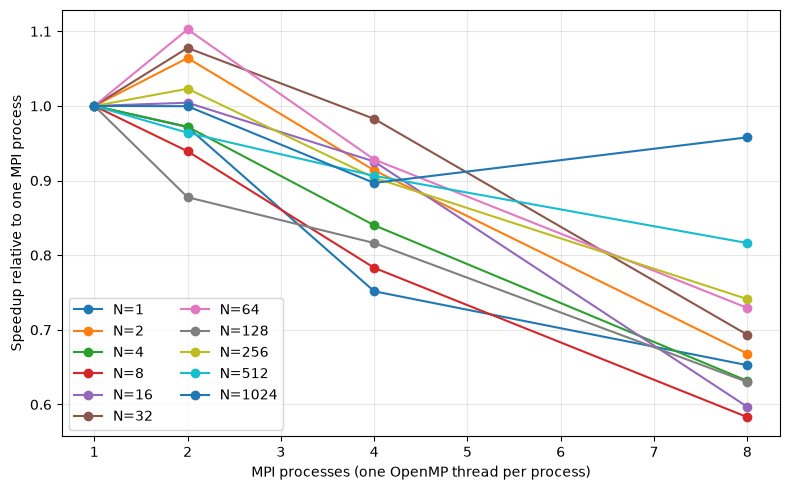

Fastest measured configuration for each ion count:


,ion_number,mpi_processes,omp_threads,t_wall_step_median
0,1,1,1,0.131875
11,2,2,1,0.127290
17,4,1,8,0.123353
22,8,1,2,0.124516
31,16,1,8,0.132413
39,32,2,1,0.136330
46,64,2,1,0.142491
49,128,1,1,0.140131
57,256,1,2,0.164586
65,512,1,4,0.217933


In [11]:
if "grouped" in globals() and not grouped.empty:
    fig, ax = plt.subplots(figsize=(12, 5))
    for (m, t), frame in grouped.groupby(["mpi_processes", "omp_threads"]):
        frame = frame.sort_values("ion_number")
        ax.loglog(frame.ion_number, frame.t_wall_step_median, "o-",
                  label=f"{m} MPI ranks × {t} OpenMP threads")
    ax.set_xlabel(r"$N$, ion number")
    ax.set_ylabel("time-per-step, s")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    fig.tight_layout()
    fig.savefig(bench_dir / f"wall_time_per_step_steps{STEPS}.png", dpi=220)
    plt.show()

    fig, ax = plt.subplots(figsize=(8, 5))
    for n, frame in grouped.groupby("ion_number"):
        frame = frame.loc[frame.omp_threads == 1].sort_values("mpi_processes")
        if frame.speedup.notna().any():
            ax.plot(frame.mpi_processes, frame.speedup, "o-", label=f"N={n}")
    x = np.array(MPI_PROCESSES)
    ax.set_xlabel("MPI processes (one OpenMP thread per process)")
    ax.set_ylabel("Speedup relative to one MPI process")
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=2)
    fig.tight_layout()
    fig.savefig(bench_dir / f"mpi_speedup_steps{STEPS}.png", dpi=220)
    plt.show()

    best = grouped.loc[grouped.groupby("ion_number").t_wall_step_median.idxmin(),
                       ["ion_number", "mpi_processes", "omp_threads", "t_wall_step_median"]]
    print("Fastest measured configuration for each ion count:")
    display(best.sort_values("ion_number"))


In [ ]:
# Compare medians from 1-step and 10001-step runs with identical (N, MPI, OMP).
records = [json.loads(path.read_text(encoding="utf-8"))
           for path in sorted(cases_dir.glob("*.json"))]
all_ok = pd.DataFrame(records)
if all_ok.empty:
    print("No timing results yet.")
else:
    all_ok = all_ok.loc[all_ok.status.eq("ok") & all_ok.steps.isin([1, 11])]
    medians = (all_ok.groupby(["ion_number", "mpi_processes", "omp_threads", "steps"])
                    .execute_wall_s.median().unstack("steps"))
    medians = medians.rename(columns={1: "median_1step_s", 10001: "median_10001steps_s"})
    if {"median_1step_s", "median_10001steps_s"}.issubset(medians.columns):
        net = medians.dropna(subset=["median_1step_s", "median_10001steps_s"]).copy()
        net["incremental_s_per_step"] = (net["median_10001steps_s"] - net["median_1step_s"]) / 10000
        if (net["incremental_s_per_step"] < 0).any():
            print("WARNING: some long-run medians are shorter than their one-step baselines.")
        net = net.reset_index().sort_values(["ion_number", "mpi_processes", "omp_threads"])
        display(net)
        net.to_csv(bench_dir / "median_subtracted_times.csv", index=False)
        print(f"Paired configurations: {len(net)} (of {len(medians)} measured configurations)")
    else:
        print("Run both STEPS=1 and STEPS=10001 to calculate the subtracted time.")

steps,ion_number,mpi_processes,omp_threads,median_1step_s,median_10001steps_s,incremental_s_per_step
0,1,1,1,0.153691,0.226730,0.007304
1,1,2,1,0.169555,0.208749,0.003919
2,1,2,2,0.159536,0.224599,0.006506
3,1,4,1,0.182253,0.238921,0.005667
4,1,4,2,0.172464,0.257589,0.008512
...,...,...,...,...,...,...
130,256,16,1,0.444980,0.779425,0.033445
131,256,16,2,0.435077,0.763532,0.032846
132,256,16,4,0.423815,0.717128,0.029331
133,256,16,8,0.448521,0.734810,0.028629


Paired configurations: 135 (of 135 measured configurations)


### Before interpreting the figures

- The subtraction `(median_10001steps_s - median_1step_s)/10000` estimates **incremental end-to-end wall time per step**, including any step-dependent output. It does not isolate LAMMPS force-calculation time.
- This benchmark measures ion-dynamics execution, not SION geometry and voltage optimization, which occur before the timer. Record CPU model, physical cores, OS, MS-MPI/LAMMPS build, and SION commit.